# Brain-Diffuser **Stage 2** — Versatile Diffusion (high-level)

**Pipeline**
```
test fMRI --ridge--> predicted CLIP-vision  --+
test fMRI --ridge--> predicted CLIP-text    --+--> Versatile Diffusion (dual-guided)
Stage-1 VDVAE reconstruction ----------------+     initialised from the VDVAE image
                                                   |
                                                   +--> results/versatile_diffusion/subj01/*.png
```


## 1. Check the GPU and RAM

In [1]:
import torch, psutil
if torch.cuda.is_available():
    p = torch.cuda.get_device_properties(0)
    gb = p.total_memory/1e9
    print(f"GPU: {p.name} ({gb:.0f} GB)")
    if gb < 20:
        print("WARNING: <20 GB GPU. The VD reconstruction step likely OOMs. "
              "Switch to L4 (24 GB) via Runtime > Change runtime type.")
    else:
        print("GPU size OK for Versatile Diffusion.")
else:
    print("No GPU. Set Runtime > Change runtime type > GPU (L4).")
ram = psutil.virtual_memory().total/1e9
print(f"System RAM: {ram:.0f} GB", "(High-RAM OK)" if ram > 40 else "(switch to High-RAM)")

GPU: NVIDIA L4 (24 GB)
GPU size OK for Versatile Diffusion.
System RAM: 57 GB (High-RAM OK)


## 2. Mount Google Drive

In [2]:
import os
from google.colab import drive
drive.mount("/content/drive")
DRIVE_DIR = "/content/drive/MyDrive/brain-diffuser-data"
print("Drive store:", DRIVE_DIR)

Mounted at /content/drive
Drive store: /content/drive/MyDrive/brain-diffuser-data


## 3. Clone the repo, link Drive, and pre-patch the scripts

Links the persistent folders (including the Stage-1 outputs) and the new
`versatile_diffusion/pretrained` into Drive. Patches the `-sub` int bug and the missing `data/`
prefix on the CLIP regressions' fMRI paths.

In [3]:
REPO = "/content/brain-diffuser"
COMMIT = "671f1403fe2a0515771c29d64fb839153cf12f5e"
import shutil, glob as _glob

if not os.path.isdir(REPO):
    !git clone https://github.com/ozcelikfu/brain-diffuser.git {REPO}
    !cd {REPO} && git checkout {COMMIT}

links = {
    f"{REPO}/vdvae/model":               f"{DRIVE_DIR}/model",
    f"{REPO}/data/processed_data":       f"{DRIVE_DIR}/processed_data",
    f"{REPO}/data/extracted_features":   f"{DRIVE_DIR}/extracted_features",
    f"{REPO}/data/predicted_features":   f"{DRIVE_DIR}/predicted_features",
    f"{REPO}/results":                   f"{DRIVE_DIR}/results",
    f"{REPO}/versatile_diffusion/pretrained": f"{DRIVE_DIR}/vd_pretrained",
}
for link, target in links.items():
    os.makedirs(target, exist_ok=True)
    if os.path.islink(link):
        continue
    if os.path.isdir(link):
        shutil.rmtree(link)
    os.makedirs(os.path.dirname(link), exist_ok=True)
    os.symlink(target, link)
    print("linked", link, "->", target)

# VD's config loader uses paths relative to CWD (configs/model/vd.yaml, lib/.../vocab, etc.); the
# scripts run from the repo root, so expose those versatile_diffusion subdirs there via symlinks.
for _name in ["configs", "pretrained", "lib"]:
    _lk, _tg = f"{REPO}/{_name}", f"{REPO}/versatile_diffusion/{_name}"
    if os.path.lexists(_lk) and not os.path.exists(_lk):
        os.remove(_lk)
    if os.path.isdir(_tg) and not os.path.lexists(_lk):
        os.symlink(_tg, _lk); print("linked", _lk, "->", _tg)

# Ensure the optimus BERT vocab is present (the repo may not ship it).
_vocab = f"{REPO}/versatile_diffusion/lib/model_zoo/optimus_models/vocab/bert-base-cased-vocab.txt"
os.makedirs(os.path.dirname(_vocab), exist_ok=True)
if not (os.path.exists(_vocab) and os.path.getsize(_vocab) > 1000):
    import subprocess
    subprocess.run(["wget", "-q", "-O", _vocab,
                    "https://huggingface.co/bert-base-cased/resolve/main/vocab.txt"])
print("optimus vocab bytes:", os.path.getsize(_vocab) if os.path.exists(_vocab) else "MISSING")

# Pre-patch every script: int(sub), and the missing data/ prefix on fMRI load paths.
for _pp in _glob.glob(f"{REPO}/scripts/*.py") + [f"{REPO}/data/prepare_nsddata.py"]:
    _s = _o = open(_pp).read()
    _s = _s.replace("sub=args.sub", "sub=int(args.sub)")
    _s = _s.replace("'processed_data/subj{:02d}/nsd_train_fmriavg", "'data/processed_data/subj{:02d}/nsd_train_fmriavg")
    _s = _s.replace("'processed_data/subj{:02d}/nsd_test_fmriavg",  "'data/processed_data/subj{:02d}/nsd_test_fmriavg")
    if _s != _o:
        open(_pp, "w").write(_s); print("patched", os.path.basename(_pp))

%cd {REPO}
!ls

Cloning into '/content/brain-diffuser'...
remote: Enumerating objects: 428, done.
remote: Counting objects: 100% (428/428), done.
remote: Compressing objects: 100% (279/279), done.
remote: Total 428 (delta 157), reused 390 (delta 132), pack-reused 0 (from 0)
Receiving objects: 100% (428/428), 6.15 MiB | 18.35 MiB/s, done.
Resolving deltas: 100% (157/157), done.
Note: switching to '671f1403fe2a0515771c29d64fb839153cf12f5e'.

You are in 'detached HEAD' state. You can look around, make experimental
changes and commit them, and you can discard any commits you make in this
state without impacting any branches by switching back to a branch.

If you want to create a new branch to retain commits you create, you may
do so (now or later) by using -c with the switch command. Example:

  git switch -c <new-branch-name>

Or undo this operation with:

  git switch -

Turn off this advice by setting config variable advice.detachedHead to false

HEAD is now at 671f140 Versatile Diffusion modules are a

## 4. Install dependencies for Versatile Diffusion

The VD code (`versatile_diffusion/lib/...`) needs these. Dependency friction is the most likely
snag — if a later cell raises `ModuleNotFoundError`, pip install that one name and re-run.

In [4]:
!pip install -q omegaconf einops pytorch-lightning transformers kornia scikit-image ftfy regex open-clip-torch sentencepiece timm
!pip install -q git+https://github.com/openai/CLIP.git   # VD's clip_frozen imports openai 'clip'
print("Installed. If a VD cell later errors on a missing module, pip install that name.")

  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done
Installed. If a VD cell later errors on a missing module, pip install that name.


## 5. Config, Stage-1 prerequisite check, and caption regeneration

Checks the true Stage-1 outputs (images, fMRI, VDVAE reconstructions) are on Drive. If the
**caption** files are missing — Stage 1 skips them when the annotations file was absent — this
cell regenerates them from `nsd_expdesign.mat` + the Hugging Face annotations (no betas needed),
reproducing `prepare_nsddata.py`'s exact indexing so captions line up with your saved images.

In [5]:
import numpy as np
from scipy.io import loadmat
SUB = 1
PROCESSED = f"{REPO}/data/processed_data/subj{SUB:02d}"

# --- true Stage-1 prerequisites ---
need = [f"{PROCESSED}/nsd_train_stim_sub{SUB}.npy",
        f"{PROCESSED}/nsd_test_stim_sub{SUB}.npy",
        f"{PROCESSED}/nsd_train_fmriavg_nsdgeneral_sub{SUB}.npy",
        f"{REPO}/results/vdvae/subj{SUB:02d}/0.png"]
for p in need:
    print(("  OK  " if os.path.exists(p) else "  MISSING ") + p)
missing = [p for p in need if not os.path.exists(p)]
assert not missing, "Run Stage 1 first (processed_data + results/vdvae must be on Drive)."

# output dirs the scripts don't create themselves
for dd in [f"{REPO}/data/extracted_features/subj{SUB:02d}",
           f"{REPO}/data/predicted_features/subj{SUB:02d}",
           f"{REPO}/results/versatile_diffusion/subj{SUB:02d}"]:
    os.makedirs(dd, exist_ok=True)

# --- captions: regenerate if missing (Stage 1 skips them without the annotations file) ---
ANNOTS_URL = "https://huggingface.co/datasets/pscotti/naturalscenesdataset/resolve/main/COCO_73k_annots_curated.npy"
cap_tr_p, cap_te_p = f"{PROCESSED}/nsd_train_cap_sub{SUB}.npy", f"{PROCESSED}/nsd_test_cap_sub{SUB}.npy"
if os.path.exists(cap_tr_p) and os.path.exists(cap_te_p):
    print("captions present.")
else:
    print("captions missing -> regenerating (no betas needed)...")
    exp = f"{REPO}/data/nsddata/experiments/nsd/nsd_expdesign.mat"
    ann = f"{REPO}/data/annots/COCO_73k_annots_curated.npy"
    os.makedirs(os.path.dirname(exp), exist_ok=True); os.makedirs(os.path.dirname(ann), exist_ok=True)
    if not os.path.exists(exp):
        !wget -q -O {exp} "https://natural-scenes-dataset.s3.amazonaws.com/nsddata/experiments/nsd/nsd_expdesign.mat"
    if not (os.path.exists(ann) and os.path.getsize(ann) > 1e6):
        !wget -q -O {ann} "{ANNOTS_URL}"
    so = loadmat(exp)
    mo = np.asarray(so['masterordering']).squeeze(); subjectim = np.asarray(so['subjectim'])
    sig_train, sig_test = {}, {}
    for idx in range(37*750):
        nsdId = int(subjectim[SUB-1, mo[idx]-1] - 1)
        (sig_train if mo[idx] > 1000 else sig_test).setdefault(nsdId, []).append(idx)
    tr, te = list(sig_train.keys()), list(sig_test.keys())
    annots_cur = np.load(ann, allow_pickle=True)
    cap_tr = np.empty((len(tr),5), dtype=annots_cur.dtype)
    for i,ix in enumerate(tr): cap_tr[i] = annots_cur[ix]
    cap_te = np.empty((len(te),5), dtype=annots_cur.dtype)
    for i,ix in enumerate(te): cap_te[i] = annots_cur[ix]
    np.save(cap_tr_p, cap_tr); np.save(cap_te_p, cap_te)
    print(f"regenerated captions: train {cap_tr.shape}, test {cap_te.shape} | example: {cap_te[0]}")

  OK  /content/brain-diffuser/data/processed_data/subj01/nsd_train_stim_sub1.npy
  OK  /content/brain-diffuser/data/processed_data/subj01/nsd_test_stim_sub1.npy
  OK  /content/brain-diffuser/data/processed_data/subj01/nsd_train_fmriavg_nsdgeneral_sub1.npy
  OK  /content/brain-diffuser/results/vdvae/subj01/0.png
captions present.


## 6. Versatile Diffusion checkpoints

VD is assembled from sub-models, each needing its own weight file in
`versatile_diffusion/pretrained/`: the main VD UNet, `kl-f8.pth` (image VAE), `optimus-vae.pth`
(text VAE). **Important:** the main checkpoint must be the **`-deprecated`** fp16 file. SHI-Labs
later refactored the VD architecture and reused the plain `vd-four-flow-v1-0-fp16.pth` name for
the new format, whose keys (`diffuser.image.data_blocks...`) do NOT match this repo's older code
(`model.diffusion_model.unet_image.input_blocks...`) — loading it leaves the UNet on random
weights and every reconstruction comes out as pure noise. The old-format file is still on the Hub
as `vd-four-flow-v1-0-fp16-deprecated.pth`; we download it and save it under the name the script
loads. CLIP auto-downloads separately. All persist on Drive.

In [6]:
VD_BASE = "https://huggingface.co/shi-labs/versatile-diffusion/resolve/main/pretrained_pth"
# dst filename -> source filename on the Hub. The main VD checkpoint uses the -deprecated (old
# architecture) file, which is what this repo's frozen code expects.
VD_FILES = {"vd-four-flow-v1-0-fp16.pth": "vd-four-flow-v1-0-fp16-deprecated.pth",
            "kl-f8.pth": "kl-f8.pth",
            "optimus-vae.pth": "optimus-vae.pth"}
pre = f"{REPO}/versatile_diffusion/pretrained"
os.makedirs(pre, exist_ok=True)
for dst_fn, src_fn in VD_FILES.items():
    dst = f"{pre}/{dst_fn}"
    if os.path.exists(dst) and os.path.getsize(dst) > 1e6:
        print(f"have {dst_fn} ({os.path.getsize(dst)/1e9:.2f} GB)")
    else:
        !wget -q --show-progress -O {dst} "{VD_BASE}/{src_fn}"
        print(f"downloaded {src_fn} -> {dst_fn}")
!ls -lh {pre}

have vd-four-flow-v1-0-fp16.pth (6.66 GB)
have kl-f8.pth (0.33 GB)
have optimus-vae.pth (1.02 GB)
lrwxrwxrwx 1 root root 56 Nov 18 21:56 /content/brain-diffuser/versatile_diffusion/pretrained -> /content/drive/MyDrive/brain-diffuser-data/vd_pretrained


## 7. Extract CLIP features (vision + text)

Runs the training/test images through VD's CLIP-vision encoder and the captions through its
CLIP-text encoder, saving the regression targets. Batch size is 1 (per the repo); one pass over
~9.8k images, so this takes a while. Needs the VD checkpoint from §6.

In [7]:
# Error-proof the VISION extraction: prereq checks (clear message, not a deep traceback),
# output dir, float64->float32 downcast (~14 GB -> 7 GB), run, verify.
import os, re
_sp = f"{REPO}/scripts/clipvision_extract_features.py"
_ckpt = f"{REPO}/versatile_diffusion/pretrained/vd-four-flow-v1-0-fp16.pth"
_bad = [m for ok, m in [
    (os.path.exists(_ckpt) and os.path.getsize(_ckpt) > 1e6, f"VD checkpoint missing -> run section 6: {_ckpt}"),
    (os.path.exists(f"{PROCESSED}/nsd_train_stim_sub{SUB}.npy"), f"Stage-1 stimuli missing -> {PROCESSED}"),
] if not ok]
assert not _bad, "FIX FIRST:\n  - " + "\n  - ".join(_bad)
os.makedirs(f"{REPO}/data/extracted_features/subj{SUB:02d}", exist_ok=True)

_s = open(_sp).read()
_s = _s.replace("sub=args.sub", "sub=int(args.sub)")
_s = re.sub(r"np\.zeros\(\(num_train,\s*num_embed,\s*num_features\)\)",
            "np.zeros((num_train,num_embed,num_features),dtype=np.float32)", _s)
_s = re.sub(r"np\.zeros\(\(num_test,\s*num_embed,\s*num_features\)\)",
            "np.zeros((num_test,num_embed,num_features),dtype=np.float32)", _s)
open(_sp, "w").write(_s)

print("extracting CLIP-vision features (train + test images through VD's vision encoder)...")
!cd {REPO} && python -u scripts/clipvision_extract_features.py -sub {SUB}

import numpy as np
for _p in [f"{REPO}/data/extracted_features/subj{SUB:02d}/nsd_clipvision_train.npy",
           f"{REPO}/data/extracted_features/subj{SUB:02d}/nsd_clipvision_test.npy"]:
    assert os.path.exists(_p), f"NOT WRITTEN: {_p}"
    print("  OK  ", _p, np.load(_p, mmap_mode="r").shape)

Streaming output truncated to the last 5000 lines.
3861
3862
3863
3864
3865
3866
3867
3868
3869
3870
3871
3872
3873
3874
3875
3876
3877
3878
3879
3880
3881
3882
3883
3884
3885
3886
3887
3888
3889
3890
3891
3892
3893
3894
3895
3896
3897
3898
3899
3900
3901
3902
3903
3904
3905
3906
3907
3908
3909
3910
3911
3912
3913
3914
3915
3916
3917
3918
3919
3920
3921
3922
3923
3924
3925
3926
3927
3928
3929
3930
3931
3932
3933
3934
3935
3936
3937
3938
3939
3940
3941
3942
3943
3944
3945
3946
3947
3948
3949
3950
3951
3952
3953
3954
3955
3956
3957
3958
3959
3960
3961
3962
3963
3964
3965
3966
3967
3968
3969
3970
3971
3972
3973
3974
3975
3976
3977
3978
3979
3980
3981
3982
3983
3984
3985
3986
3987
3988
3989
3990
3991
3992
3993
3994
3995
3996
3997
3998
3999
4000
4001
4002
4003
4004
4005
4006
4007
4008
4009
4010
4011
4012
4013
4014
4015
4016
4017
4018
4019
4020
4021
4022
4023
4024
4025
4026
4027
4028
4029
4030
4031
4032
4033
4034
4035
4036
4037
4038
4039
4040
4041
4042
4043
4044
4045
4046
4047
4048
4049
4050

In [8]:
# Error-proof the text extraction: check every prerequisite up front (so you get a clear
# message, not a deep traceback), ensure the output dir, downcast the feature array to float32,
# then run and verify the outputs exist.
import os, re
_sp = f"{REPO}/scripts/cliptext_extract_features.py"

# 1. prerequisites -- the exact things that make the script crash if absent
_ckpt   = f"{REPO}/versatile_diffusion/pretrained/vd-four-flow-v1-0-fp16.pth"
_cap_tr = f"{PROCESSED}/nsd_train_cap_sub{SUB}.npy"
_cap_te = f"{PROCESSED}/nsd_test_cap_sub{SUB}.npy"
_problems = []
if not (os.path.exists(_ckpt) and os.path.getsize(_ckpt) > 1e6):
    _problems.append(f"VD checkpoint missing/incomplete: {_ckpt}  -> run section 6.")
if not os.path.exists(_cap_tr) or not os.path.exists(_cap_te):
    _problems.append(f"caption files missing in {PROCESSED}  -> run section 5 (caption regen).")
assert not _problems, "FIX THESE FIRST:\n  - " + "\n  - ".join(_problems)

# 2. output dir (np.save does not create it)
os.makedirs(f"{REPO}/data/extracted_features/subj{SUB:02d}", exist_ok=True)

# 3. idempotent patches: -sub int cast + float64 feature array -> float32 (~half the RAM).
#    Whitespace-tolerant so it matches regardless of how the repo formatted the np.zeros call;
#    if it somehow does not match, the script still runs (just at float64), so this is safe.
_s = _o = open(_sp).read()
_s = _s.replace("sub=args.sub", "sub=int(args.sub)")
# repo bug: the test loop iterates `val_caps`, a name that is never defined (the file only loads
# train_caps/test_caps). It should be test_caps. Fix it so the script doesn't NameError.
_s = _s.replace("val_caps", "test_caps")
_before = _s
_s = re.sub(r"np\.zeros\(\(num_train,\s*num_embed,\s*num_features\)\)",
            "np.zeros((num_train,num_embed,num_features),dtype=np.float32)", _s)
_s = re.sub(r"np\.zeros\(\(num_test,\s*num_embed,\s*num_features\)\)",
            "np.zeros((num_test,num_embed,num_features),dtype=np.float32)", _s)
if _s != _o:
    open(_sp, "w").write(_s)
print("float32 downcast applied." if _s != _before else "float32 pattern not found (running float64 -- fine at 50 GB RAM).")

# 4. run
print("prerequisites OK -> encoding captions through VD's CLIP-text encoder...")
!cd {REPO} && python scripts/cliptext_extract_features.py -sub {SUB}

# 5. verify the outputs the regression will need
import numpy as np
_ok = True
for _p in [f"{REPO}/data/extracted_features/subj{SUB:02d}/nsd_cliptext_train.npy",
           f"{REPO}/data/extracted_features/subj{SUB:02d}/nsd_cliptext_test.npy"]:
    if os.path.exists(_p):
        print("  OK  ", _p, np.load(_p, mmap_mode="r").shape)
    else:
        print("  MISSING ", _p); _ok = False
assert _ok, "Extraction did not produce the text features -- check the traceback above."

Streaming output truncated to the last 5000 lines.
3861
3862
3863
3864
3865
3866
3867
3868
3869
3870
3871
3872
3873
3874
3875
3876
3877
3878
3879
3880
3881
3882
3883
3884
3885
3886
3887
3888
3889
3890
3891
3892
3893
3894
3895
3896
3897
3898
3899
3900
3901
3902
3903
3904
3905
3906
3907
3908
3909
3910
3911
3912
3913
3914
3915
3916
3917
3918
3919
3920
3921
3922
3923
3924
3925
3926
3927
3928
3929
3930
3931
3932
3933
3934
3935
3936
3937
3938
3939
3940
3941
3942
3943
3944
3945
3946
3947
3948
3949
3950
3951
3952
3953
3954
3955
3956
3957
3958
3959
3960
3961
3962
3963
3964
3965
3966
3967
3968
3969
3970
3971
3972
3973
3974
3975
3976
3977
3978
3979
3980
3981
3982
3983
3984
3985
3986
3987
3988
3989
3990
3991
3992
3993
3994
3995
3996
3997
3998
3999
4000
4001
4002
4003
4004
4005
4006
4007
4008
4009
4010
4011
4012
4013
4014
4015
4016
4017
4018
4019
4020
4021
4022
4023
4024
4025
4026
4027
4028
4029
4030
4031
4032
4033
4034
4035
4036
4037
4038
4039
4040
4041
4042
4043
4044
4045
4046
4047
4048
4049
4050

## 8. Train the fMRI -> CLIP regressions

Ridge regressions from fMRI to the CLIP-vision and CLIP-text features. The **vision** one is
memory-heavy (~20+ GB coefficient matrix) — this is why High-RAM matters. fMRI paths are already
patched to `data/processed_data/`.

In [9]:
# Patch inline (same bugs as every repo script): -sub read as a string, and the fMRI load
# paths missing the 'data/' prefix. Idempotent — re-running does nothing if already patched.
_rp = f"{REPO}/scripts/clipvision_regression.py"
_s = open(_rp).read()
_s = _s.replace("sub=args.sub", "sub=int(args.sub)")
_s = _s.replace("'processed_data/subj{:02d}/nsd_train_fmriavg", "'data/processed_data/subj{:02d}/nsd_train_fmriavg")
_s = _s.replace("'processed_data/subj{:02d}/nsd_test_fmriavg",  "'data/processed_data/subj{:02d}/nsd_test_fmriavg")
open(_rp, "w").write(_s)
!cd {REPO} && python scripts/clipvision_regression.py -sub {SUB}

-4.345760117042555e-16 0.9999435586284298
-0.027261797786477315 0.9914779354685913
24.4805317560972 -14.412738287655525
9.81827287708914 -9.315348672150476
Training Regression
0 0.09548248621993582
1 0.06342827303502369
2 0.07109977967468545
3 0.070111057387488
4 0.08466557092720069
5 0.08444206417578003
6 0.07393335981403587
7 0.0928798831242539
8 0.07924466716665661
9 0.03923165600714524
10 0.08496646982345185
11 0.0706998554244254
12 0.06823073053656818
13 0.07015772532375449
14 0.0841140770299792
15 0.06360040653881611
16 0.07064653730921748
17 0.08050681563229317
18 0.048705129780508734
19 0.05526956397190058
20 0.04884357312586974
21 0.04935014906277716
22 0.08878266089072069
23 0.0427699263956737
24 0.04364668570539374
25 0.06675026018919696
26 0.02595248544768101
27 0.030171348299515035
28 0.02990327385816194
29 0.06459651266862874
30 0.046029062264076374
31 0.0824100308647024
32 0.06919869007700113
33 0.08414869131858756
34 0.06609691124030788
35 0.08152410244949458
36 0.05548

In [ ]:
# cliptext_regression.py has the identical two bugs (same fMRI path strings as the vision one);
# apply the same inline patch, then run.
_rp = f"{REPO}/scripts/cliptext_regression.py"
_s = open(_rp).read()
_s = _s.replace("sub=args.sub", "sub=int(args.sub)")
_s = _s.replace("'processed_data/subj{:02d}/nsd_train_fmriavg", "'data/processed_data/subj{:02d}/nsd_train_fmriavg")
_s = _s.replace("'processed_data/subj{:02d}/nsd_test_fmriavg",  "'data/processed_data/subj{:02d}/nsd_test_fmriavg")
open(_rp, "w").write(_s)
!cd {REPO} && python scripts/cliptext_regression.py -sub {SUB}

-4.345760117042555e-16 0.9999435586284298
-0.027261797786477315 0.9914779354685913
24.4805317560972 -14.412738287655525
9.81827287708914 -9.315348672150476
Training Regression
0 0.06254215165523928
1 0.030264865826704082
2 0.05509220903059342
3 0.05893065094440744
4 0.062236537883328245
5 0.06399112638759656
6 0.06306401426861451
7 0.06702273611497439
8 0.06614513187244471
9 0.06831857123748813
10 0.07916958845561967
11 0.09509878933213484
12 0.11345085556380434
13 0.1281604182234678
14 0.13754202338823374
15 0.1420431675301314
16 0.1458504851989203
17 0.14883877047974162
18 0.15067042309081477
19 0.15154800439651542
20 0.1517414284098476
21 0.15190130040958524
22 0.1518330146196799
23 0.1519256204555586
24 0.15195881434633332
25 0.1521684809956808
26 0.15202440144473925
27 0.1517137966654705
28 0.15151679372495389
29 0.15131222469976813
30 0.15118396170911697
31 0.15099283691545531
32 0.1508083322968821
33 0.15070769896516942
34 0.15062687464538035
35 0.1505987922303265
36 0.150594658

## 9. Versatile Diffusion reconstruction (the payoff)


In [ ]:

_sp = f"{REPO}/scripts/versatilediffusion_reconstruct_images.py"
_s = open(_sp).read()
_s = _s.replace("sub=args.sub", "sub=int(args.sub)")
_s = _s.replace("cuda(1)", "cuda(0)").replace("cuda:1", "cuda:0")
_s = _s.replace(".half()", ".float()")
open(_sp, "w").write(_s)

# The VD UNet lib hardcodes .half() on its activations (openaimodel.py forward/forward_dc: x and
# t_emb). Cast those to .float() too so activations match the fp32 weights.
_op = f"{REPO}/versatile_diffusion/lib/model_zoo/openaimodel.py"
_l = open(_op).read()
_nhalf = _l.count(".to(self.device).half()")
_l = _l.replace(".to(self.device).half()", ".to(self.device).float()")
open(_op, "w").write(_l)

os.makedirs(f"{REPO}/results/versatile_diffusion/subj{SUB:02d}", exist_ok=True)
print("patch | cuda(1) left:", "cuda(1)" in _s, "| script .half() left:", ".half()" in _s,
      "| UNet activation casts fixed:", _nhalf, "(expect 4)")
print("Tip: open results/versatile_diffusion/subj01/0.png after the first image to confirm it is "
      "a real reconstruction before the full 982-image run finishes.")
!cd {REPO} && python -u scripts/versatilediffusion_reconstruct_images.py -sub {SUB}

patch | cuda(1) left: False | script .half() left: False | UNet activation casts fixed: 4 (expect 4)
Tip: open results/versatile_diffusion/subj01/0.png after the first image to confirm it is a real reconstruction before the full 982-image run finishes.

#######################
# Running in eps mode #
#######################

Load openai_unet_2d with total 859520964 parameters,100560.170 parameter sum.
Load openai_unet_0dmd with total 1708848448 parameters,249398.358 parameter sum.
Load openai_unet_vd with total 2566318852 parameters,349980.385 parameter sum.
making attention of type 'vanilla' with 512 in_channels
Working with z of shape (1, 4, 32, 32) = 4096 dimensions.
making attention of type 'vanilla' with 512 in_channels
Load pth from pretrained/kl-f8.pth
Load autoencoderkl with total 83653863 parameters,72921.751 parameter sum.
Load optimus_bert_connector with total 109489920 parameters,19276.911 parameter sum.
Load optimus_gpt2_connector with total 132109824 parameters,19479.515 

## 10. Compare: seen vs Stage-1 (VDVAE) vs Stage-2 (VD)

Three rows per column — what the subject saw, the low-level reconstruction, and the final
high-level reconstruction. This is the figure for your showcase.

saved comparison figure -> /content/brain-diffuser/results/versatile_diffusion/subj01_seen_vdvae_vd.png


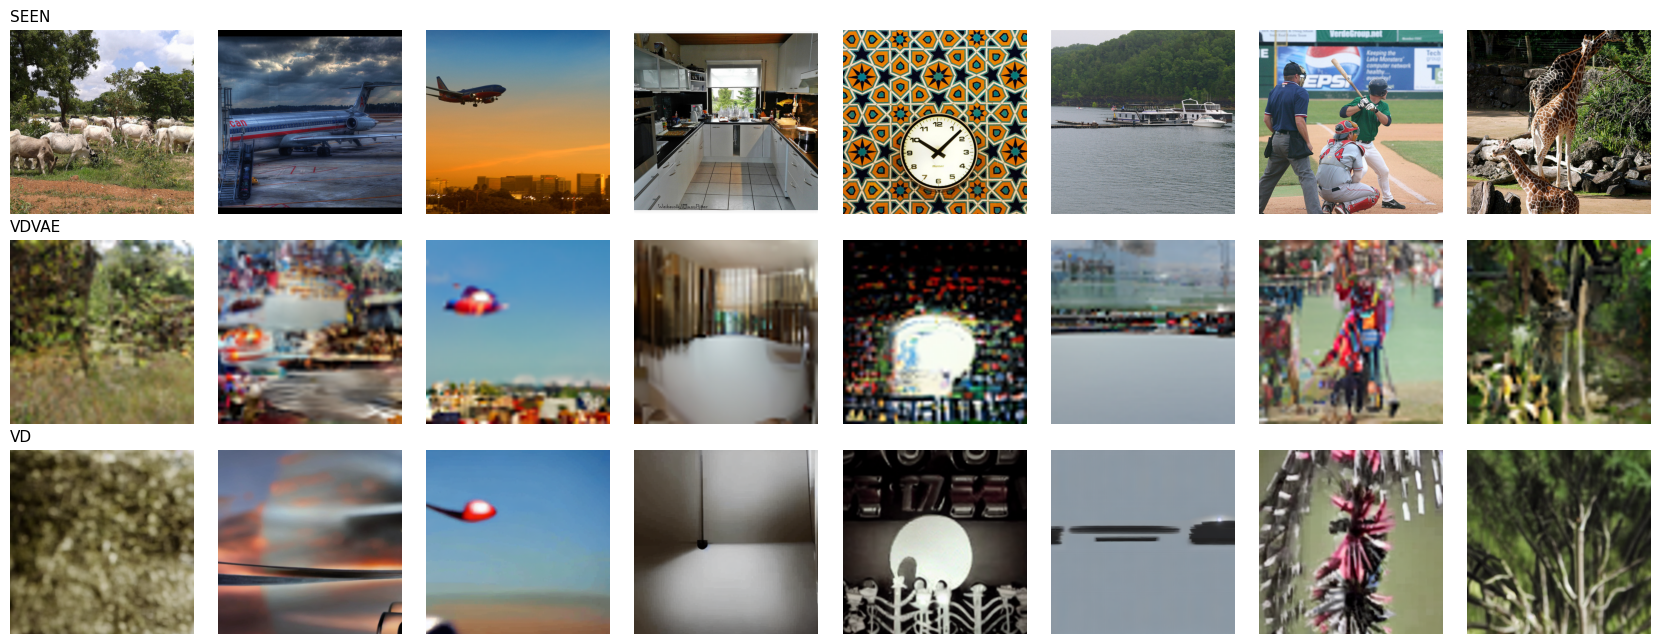

In [12]:
import numpy as np
from PIL import Image
import matplotlib.pyplot as plt

test_stim = np.load(f"{PROCESSED}/nsd_test_stim_sub{SUB}.npy")   # (982,425,425,3) uint8
vdvae_dir = f"{REPO}/results/vdvae/subj{SUB:02d}"
vd_dir    = f"{REPO}/results/versatile_diffusion/subj{SUB:02d}"

idxs = [0, 1, 2, 3, 4, 5, 6, 7]
rows = [("SEEN",   lambda j: test_stim[j]),
        ("VDVAE",  lambda j: Image.open(f"{vdvae_dir}/{j}.png")),
        ("VD",     lambda j: Image.open(f"{vd_dir}/{j}.png"))]
fig, axes = plt.subplots(3, len(idxs), figsize=(2.1*len(idxs), 6.5))
for r, (label, getter) in enumerate(rows):
    for c, j in enumerate(idxs):
        try:
            axes[r, c].imshow(getter(j))
        except FileNotFoundError:
            axes[r, c].text(0.5, 0.5, "missing", ha="center")
        axes[r, c].axis("off")
        if c == 0: axes[r, c].set_title(label, loc="left", fontsize=11)
plt.tight_layout()
out = f"{vd_dir}_seen_vdvae_vd.png"
plt.savefig(out, dpi=130, bbox_inches="tight"); print("saved comparison figure ->", out)
plt.show()